# 02 — Training on AI vs Real
**KhabarNazar — Image Analysis Module**

1. **Learning-rate experiment** — three learning rates compared on one graph
2. **Baseline comparison** — simple CNN from scratch vs ResNet18 (final layer only) vs ResNet18 (all layers)
3. **Final model** — full fine-tuning with early stopping, training curves
4. **Test-set evaluation** — accuracy, precision, recall, F1, confusion matrix, ROC, precision-recall
5. **Error analysis** — most confident mistakes and a t-SNE plot of learned features

**Input pipeline:** images are 512 px on the shorter side (notebook 01). Training uses a **random 224×224 crop**
plus horizontal flip; evaluation uses the **centre 224×224 crop**. Cropping instead of shrinking keeps the fine
pixel-level texture where AI-generation artifacts appear.

In [1]:
import json, time, random, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
                             precision_recall_curve, average_precision_score)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "ai_vs_real"
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
OUTPUTS = ROOT / "outputs"; OUTPUTS.mkdir(exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
BATCH_SIZE = 64
WORKERS = 4

GPU: NVIDIA RTX A4000


## 1. Data

In [2]:
train_tf = transforms.Compose([
    transforms.RandomCrop(224, pad_if_needed=True, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Two views of the same folder so validation images are not augmented
train_view = datasets.ImageFolder(DATA / "train", transform=train_tf)
eval_view = datasets.ImageFolder(DATA / "train", transform=eval_tf)
test_ds = datasets.ImageFolder(DATA / "test", transform=eval_tf)
CLASSES = train_view.classes
print("Classes:", train_view.class_to_idx)          # {'fake': 0, 'real': 1}

idx = np.random.RandomState(SEED).permutation(len(train_view))
n_val = len(idx) // 10                              # 10% of train held out for validation
train_ds, val_ds = Subset(train_view, idx[n_val:]), Subset(eval_view, idx[:n_val])
print(f"Train {len(train_ds)} | Val {len(val_ds)} | Test {len(test_ds)}")

kw = dict(batch_size=BATCH_SIZE, num_workers=WORKERS, pin_memory=True, persistent_workers=True)
train_loader = DataLoader(train_ds, shuffle=True, **kw)
val_loader = DataLoader(val_ds, shuffle=False, **kw)
test_loader = DataLoader(test_ds, shuffle=False, **kw)

Classes: {'fake': 0, 'real': 1}
Train 43200 | Val 4800 | Test 12000


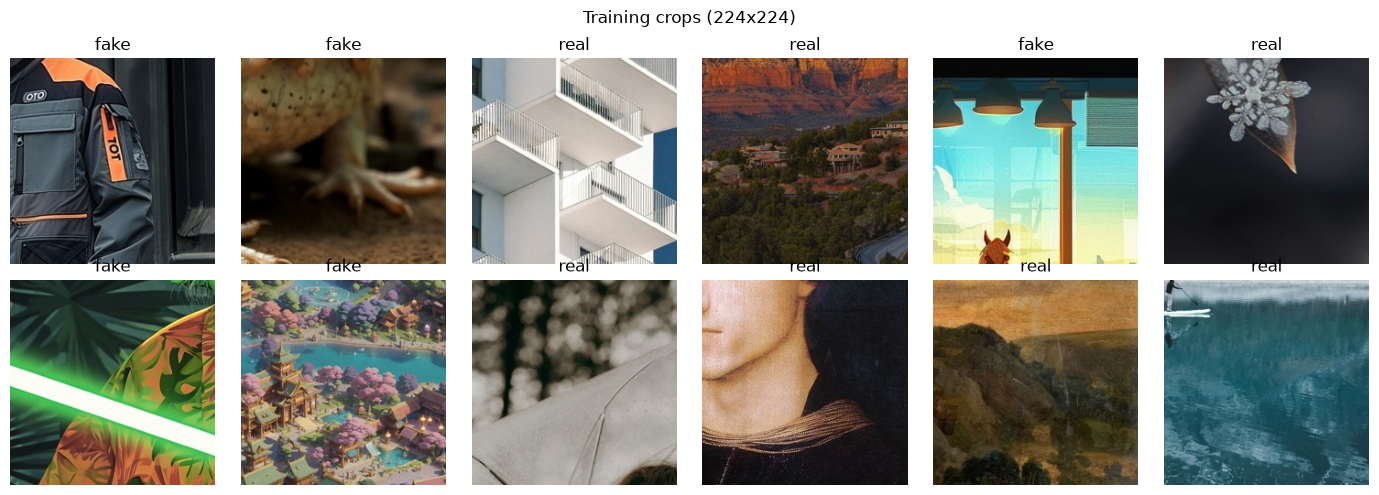

In [3]:
# What the model actually sees: random 224x224 training crops
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, img, y in zip(axes.flat, images, labels):
    img = img.permute(1, 2, 0).numpy() * STD + MEAN
    ax.imshow(img.clip(0, 1)); ax.set_title(CLASSES[y]); ax.axis("off")
plt.suptitle("Training crops (224x224)"); plt.tight_layout(); plt.show()

## 2. Models and training loop

In [4]:
class SimpleCNN(nn.Module):
    # Small CNN trained from scratch: the baseline that shows what transfer learning adds
    def __init__(self):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, 2))
    def forward(self, x):
        return self.head(self.features(x))

def make_model(kind):
    if kind == "simple_cnn":
        return SimpleCNN()
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if kind == "resnet18_head":                    # freeze everything except the new final layer
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, seen = 0.0, 0, 0
    for x, y in tqdm(loader, leave=False, desc="train" if training else "eval"):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(training), torch.amp.autocast("cuda"):
            out = model(x)
            loss = criterion(out, y)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        total_loss += loss.item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        seen += y.size(0)
    return total_loss / seen, correct / seen

def train(kind, lr, epochs, patience=None, save_as=None):
    # Train one model; keeps the weights of the best validation epoch. Returns (model, history).
    torch.manual_seed(SEED)
    model = make_model(kind).to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda")
    criterion = nn.CrossEntropyLoss()
    print(f"== {kind} | lr {lr:g} | trainable params {sum(p.numel() for p in params):,}")

    history, best_acc, best_epoch, best_state = [], 0.0, 0, None
    for epoch in range(1, epochs + 1):
        start = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        scheduler.step()
        history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc))
        print(f"epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | {(time.time() - start) / 60:.1f} min")
        if va_acc > best_acc:
            best_acc, best_epoch = va_acc, epoch
            best_state = copy.deepcopy(model.state_dict())
        elif patience and epoch - best_epoch >= patience:
            print(f"early stopping (no improvement for {patience} epochs)")
            break
    model.load_state_dict(best_state)
    print(f"best val acc {best_acc:.4f} at epoch {best_epoch}\n")
    if save_as:
        torch.save(best_state, MODELS / save_as)
        info = dict(kind=kind, lr=lr, best_epoch=best_epoch, best_val_acc=best_acc, history=history)
        (MODELS / save_as.replace(".pth", "_info.json")).write_text(json.dumps(info, indent=2))
        print("saved", MODELS / save_as)
    return model, history

def plot_histories(histories, title, file):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
    for name, h in histories.items():
        ep = [e["epoch"] for e in h]
        line, = a1.plot(ep, [e["val_loss"] for e in h], marker="o", label=name)
        a1.plot(ep, [e["train_loss"] for e in h], "--", color=line.get_color(), alpha=0.6)
        a2.plot(ep, [e["val_acc"] for e in h], marker="o", color=line.get_color(), label=name)
        a2.plot(ep, [e["train_acc"] for e in h], "--", color=line.get_color(), alpha=0.6)
    a1.set_title("Loss (solid = validation, dashed = train)"); a1.set_xlabel("epoch"); a1.legend()
    a2.set_title("Accuracy (solid = validation, dashed = train)"); a2.set_xlabel("epoch"); a2.legend()
    fig.suptitle(title); plt.tight_layout(); plt.savefig(OUTPUTS / file, dpi=120); plt.show()

## 3. Learning-rate experiment
ResNet18 with all layers trainable, 3 epochs at each of three learning rates.
The learning rate with the best validation accuracy is used for the final model.

== resnet18_full | lr 0.01 | trainable params 11,177,538


train:   0%|          | 0/675 [00:01<?, ?it/s]

eval:   0%|          | 0/75 [00:07<?, ?it/s]

epoch  1 | train loss 0.6904 acc 0.5860 | val loss 0.6593 acc 0.5969 | 7.5 min


train:   0%|          | 0/675 [00:00<?, ?it/s]

...

eval:   0%|          | 0/75 [00:00<?, ?it/s]

epoch  2 | train loss 0.2409 acc 0.8995 | val loss 0.2588 acc 0.8900 | 1.2 min


train:   0%|          | 0/675 [00:00<?, ?it/s]

eval:   0%|          | 0/75 [00:00<?, ?it/s]

epoch  3 | train loss 0.1982 acc 0.9190 | val loss 0.2049 acc 0.9181 | 1.2 min
best val acc 0.9181 at epoch 3



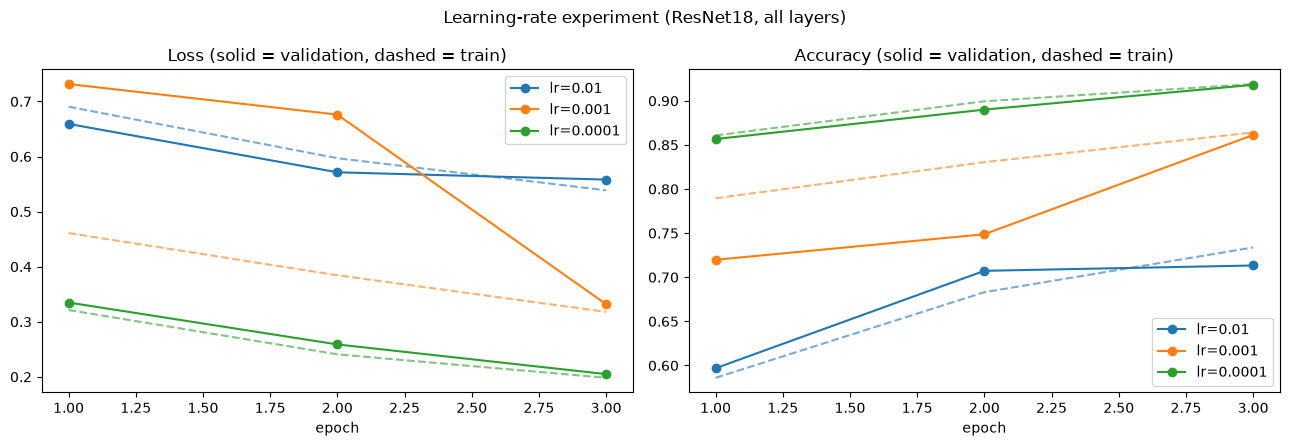

,learning rate,best val acc
0,0.0100,0.713333
1,0.0010,0.861250
2,0.0001,0.918125


Chosen learning rate: 0.0001


In [5]:
LR_EPOCHS = 3
lr_results = {}
for lr in [1e-2, 1e-3, 1e-4]:
    _, h = train("resnet18_full", lr, LR_EPOCHS)
    lr_results[lr] = h
    torch.cuda.empty_cache()

plot_histories({f"lr={k:g}": h for k, h in lr_results.items()},
               "Learning-rate experiment (ResNet18, all layers)", "02_lr_experiment.png")
lr_table = pd.DataFrame([{"learning rate": k, "best val acc": max(e["val_acc"] for e in h)}
                         for k, h in lr_results.items()])
display(lr_table)
BEST_LR = float(lr_table.loc[lr_table["best val acc"].idxmax(), "learning rate"])
print("Chosen learning rate:", BEST_LR)

## 4. Baseline comparison
Same data and number of epochs for three approaches:
- **Simple CNN** trained from scratch (no pretraining)
- **ResNet18, final layer only** (frozen ImageNet backbone, the FYP-1 approach)
- **ResNet18, all layers** fine-tuned

== simple_cnn | lr 0.001 | trainable params 389,890


train:   0%|          | 0/675 [00:00<?, ?it/s]

eval:   0%|          | 0/75 [00:00<?, ?it/s]

epoch  1 | train loss 0.5801 acc 0.7025 | val loss 0.5702 acc 0.7015 | 1.2 min


train:   0%|          | 0/675 [00:00<?, ?it/s]

...

eval:   0%|          | 0/75 [00:00<?, ?it/s]

epoch  4 | train loss 0.1787 acc 0.9277 | val loss 0.1988 acc 0.9208 | 1.3 min


train:   0%|          | 0/675 [00:00<?, ?it/s]

eval:   0%|          | 0/75 [00:00<?, ?it/s]

epoch  5 | train loss 0.1583 acc 0.9381 | val loss 0.1886 acc 0.9250 | 1.2 min
best val acc 0.9250 at epoch 5



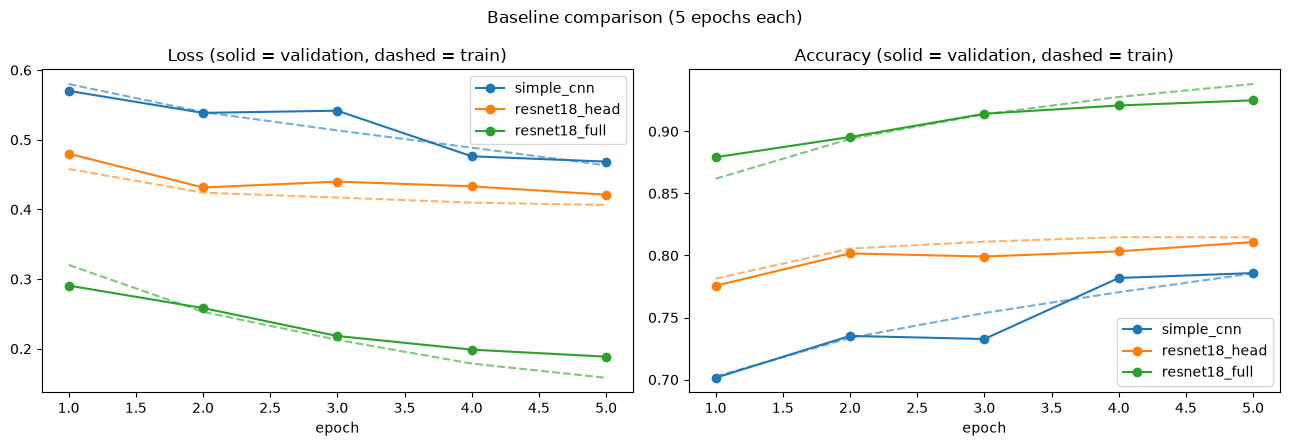

In [6]:
BASE_EPOCHS = 5
baselines, baseline_models = {}, {}
for kind, lr in [("simple_cnn", 1e-3), ("resnet18_head", 1e-3), ("resnet18_full", BEST_LR)]:
    m, h = train(kind, lr, BASE_EPOCHS, save_as=f"{kind}_ai_vs_real.pth" if kind != "resnet18_full" else None)
    baselines[kind] = h
    baseline_models[kind] = m.cpu()
    torch.cuda.empty_cache()

plot_histories(baselines, "Baseline comparison (5 epochs each)", "02_baselines.png")

## 5. Final model
ResNet18, all layers, best learning rate, up to 20 epochs with early stopping (patience 3).
Saved as `models/resnet18_ai_vs_real.pth`.

== resnet18_full | lr 0.0001 | trainable params 11,177,538


train:   0%|          | 0/675 [00:00<?, ?it/s]

eval:   0%|          | 0/75 [00:00<?, ?it/s]

epoch  1 | train loss 0.3234 acc 0.8607 | val loss 0.2738 acc 0.8860 | 1.2 min


train:   0%|          | 0/675 [00:00<?, ?it/s]

...

eval:   0%|          | 0/75 [00:00<?, ?it/s]

epoch 11 | train loss 0.1244 acc 0.9521 | val loss 0.1750 acc 0.9327 | 1.2 min


train:   0%|          | 0/675 [00:00<?, ?it/s]

eval:   0%|          | 0/75 [00:00<?, ?it/s]

epoch 12 | train loss 0.1151 acc 0.9558 | val loss 0.1747 acc 0.9358 | 1.2 min
early stopping (no improvement for 3 epochs)
best val acc 0.9375 at epoch 9

saved E:\FYP\KhabarNazar\image_module\models\resnet18_ai_vs_real.pth


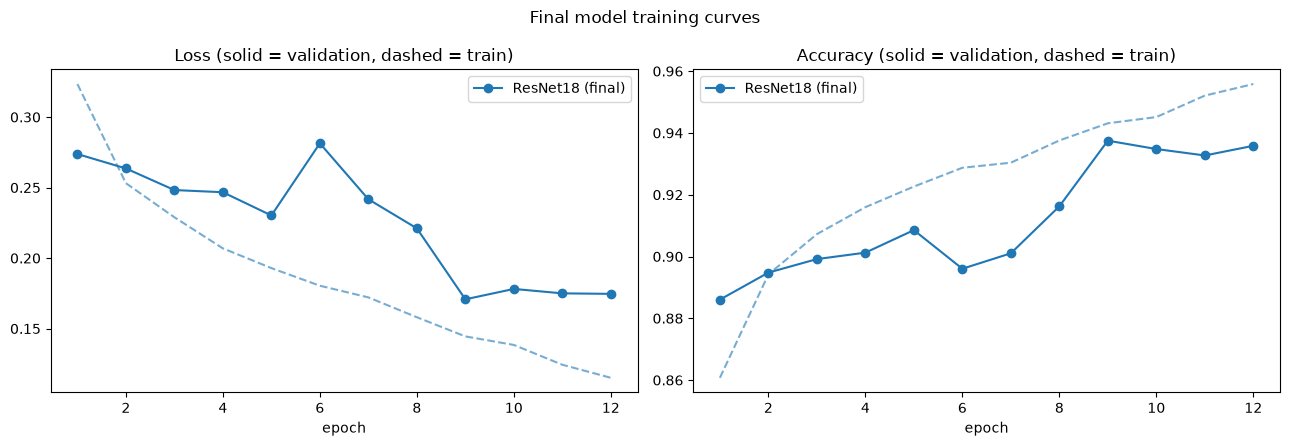

In [7]:
final_model, final_hist = train("resnet18_full", BEST_LR, epochs=20, patience=3, save_as="resnet18_ai_vs_real.pth")
plot_histories({"ResNet18 (final)": final_hist}, "Final model training curves", "02_final_curves.png")

## 6. Test-set evaluation (12,000 images never seen in training)

test:   0%|          | 0/188 [00:07<?, ?it/s]

test:   0%|          | 0/188 [00:00<?, ?it/s]

test:   0%|          | 0/188 [00:00<?, ?it/s]

,accuracy,precision,recall,F1,ROC AUC
model,,,,,
Simple CNN,0.7950,0.7980,0.7950,0.7945,0.8741
ResNet18 (final layer),0.8158,0.8175,0.8158,0.8156,0.8995
ResNet18 (all layers),0.9395,0.9395,0.9395,0.9395,0.9854


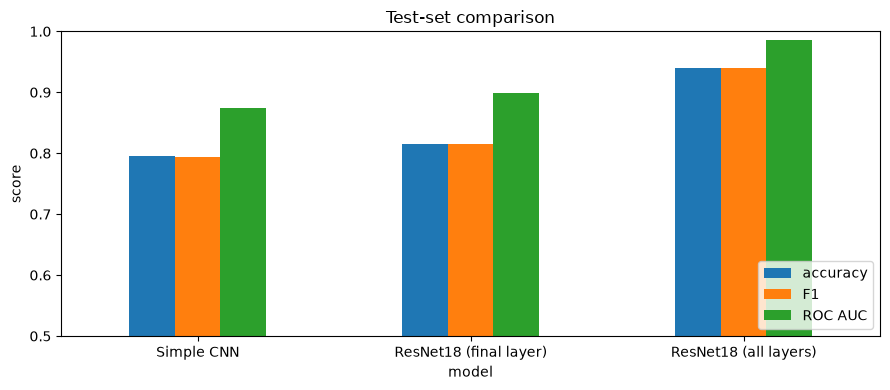

In [8]:
@torch.no_grad()
def predict(model, loader):
    model.to(device).eval()
    probs, labels = [], []
    for x, y in tqdm(loader, leave=False, desc="test"):
        with torch.amp.autocast("cuda"):
            p = torch.softmax(model(x.to(device)), 1)[:, 1]       # probability of class 1 (real)
        probs.append(p.float().cpu()); labels.append(y)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()

all_models = {"Simple CNN": baseline_models["simple_cnn"],
              "ResNet18 (final layer)": baseline_models["resnet18_head"],
              "ResNet18 (all layers)": final_model}
results, preds = [], {}
for name, m in all_models.items():
    p, y = predict(m, test_loader)
    yhat = (p >= 0.5).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(y, yhat, average="macro")
    fpr, tpr, _ = roc_curve(y, p)
    results.append({"model": name, "accuracy": accuracy_score(y, yhat), "precision": prec,
                    "recall": rec, "F1": f1, "ROC AUC": auc(fpr, tpr)})
    preds[name] = (p, y)

results_df = pd.DataFrame(results).set_index("model").round(4)
display(results_df)
results_df.to_csv(OUTPUTS / "02_test_results.csv")

results_df[["accuracy", "F1", "ROC AUC"]].plot.bar(figsize=(9, 4), rot=0, ylim=(0.5, 1.0))
plt.title("Test-set comparison"); plt.ylabel("score"); plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(OUTPUTS / "02_test_comparison.png", dpi=120); plt.show()

              precision    recall  f1-score   support

        fake     0.9395    0.9395    0.9395      6000
        real     0.9395    0.9395    0.9395      6000

    accuracy                         0.9395     12000
   macro avg     0.9395    0.9395    0.9395     12000
weighted avg     0.9395    0.9395    0.9395     12000



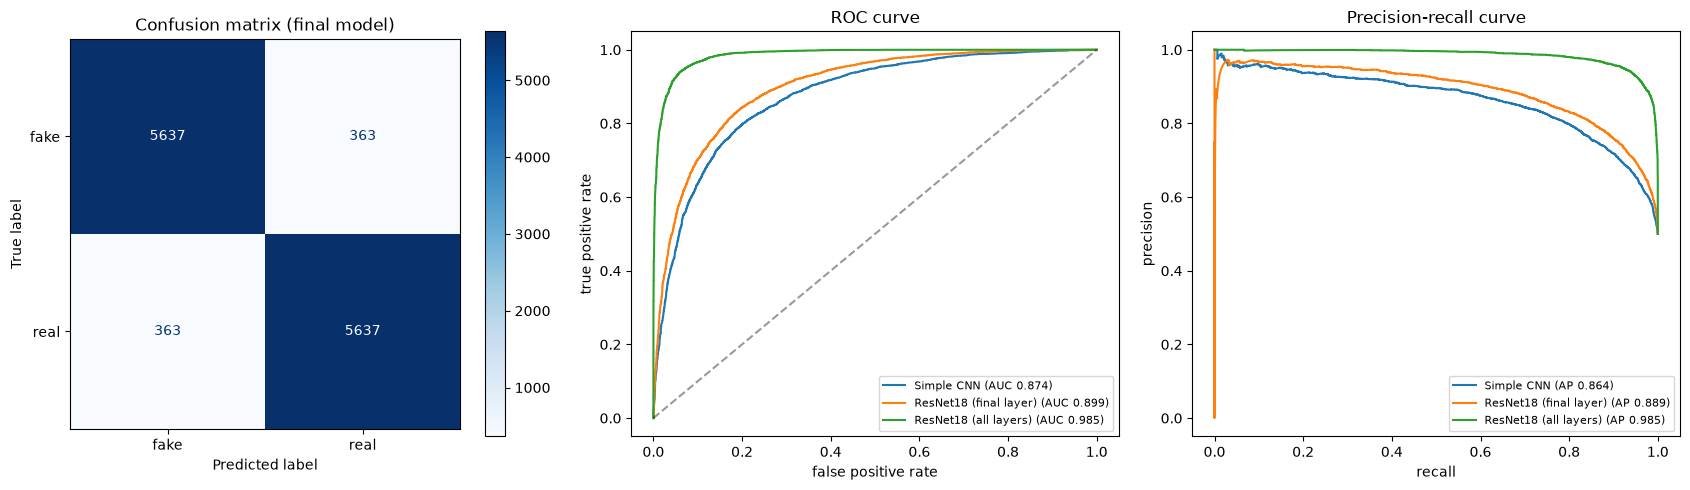

In [9]:
p, y = preds["ResNet18 (all layers)"]
yhat = (p >= 0.5).astype(int)
report = classification_report(y, yhat, target_names=CLASSES, digits=4)
print(report)
(OUTPUTS / "02_classification_report.txt").write_text(report)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ConfusionMatrixDisplay(confusion_matrix(y, yhat), display_labels=CLASSES).plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Confusion matrix (final model)")
for name, (pp, yy) in preds.items():
    fpr, tpr, _ = roc_curve(yy, pp)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC {auc(fpr, tpr):.3f})")
    pr, rc, _ = precision_recall_curve(yy, pp)
    axes[2].plot(rc, pr, label=f"{name} (AP {average_precision_score(yy, pp):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_title("ROC curve"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].legend(fontsize=8)
axes[2].set_title("Precision-recall curve"); axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision")
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUTS / "02_confusion_roc_pr.png", dpi=120); plt.show()

## 7. Error analysis

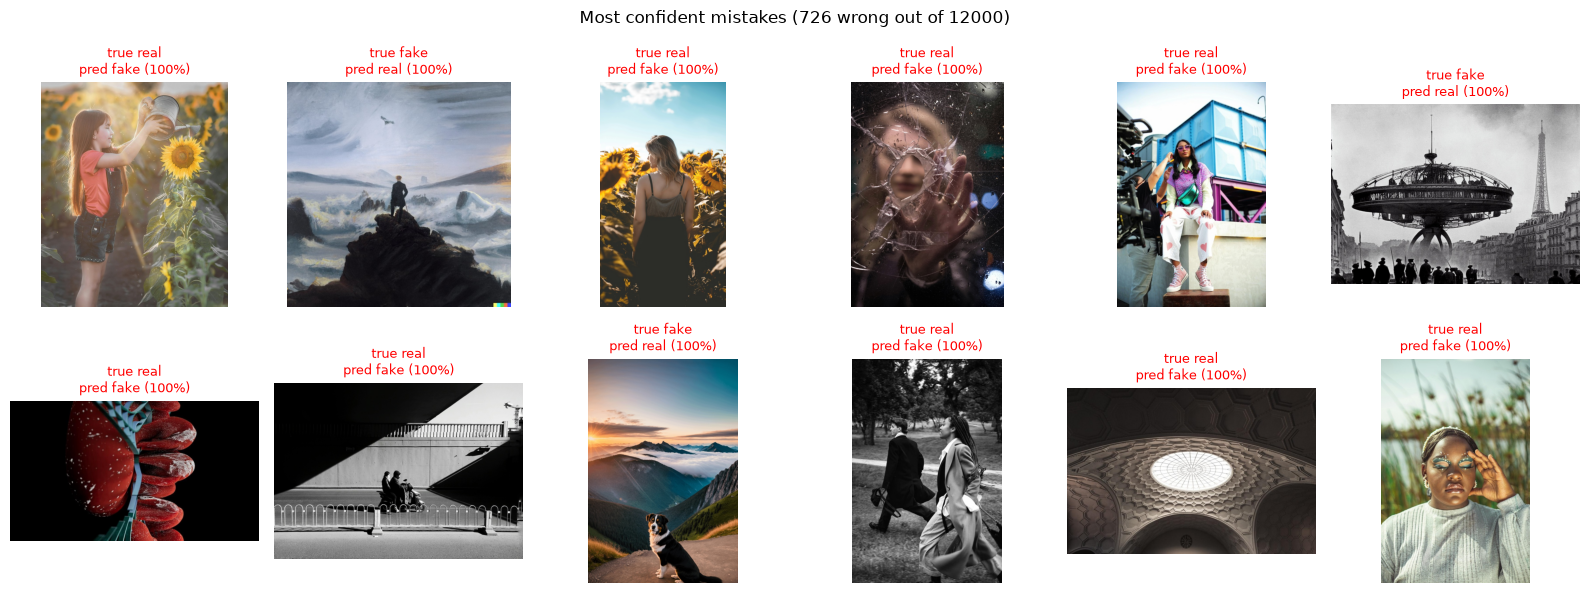

In [10]:
# Most confident mistakes of the final model
wrong = np.where(yhat != y)[0]
conf = np.where(yhat == 1, p, 1 - p)
worst = wrong[np.argsort(-conf[wrong])][:12]
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, worst):
    ax.imshow(plt.imread(test_ds.samples[i][0]))
    ax.set_title(f"true {CLASSES[y[i]]}\npred {CLASSES[yhat[i]]} ({conf[i]:.0%})", fontsize=9, color="red")
plt.suptitle(f"Most confident mistakes ({len(wrong)} wrong out of {len(y)})")
plt.tight_layout(); plt.savefig(OUTPUTS / "02_mistakes.png", dpi=120); plt.show()

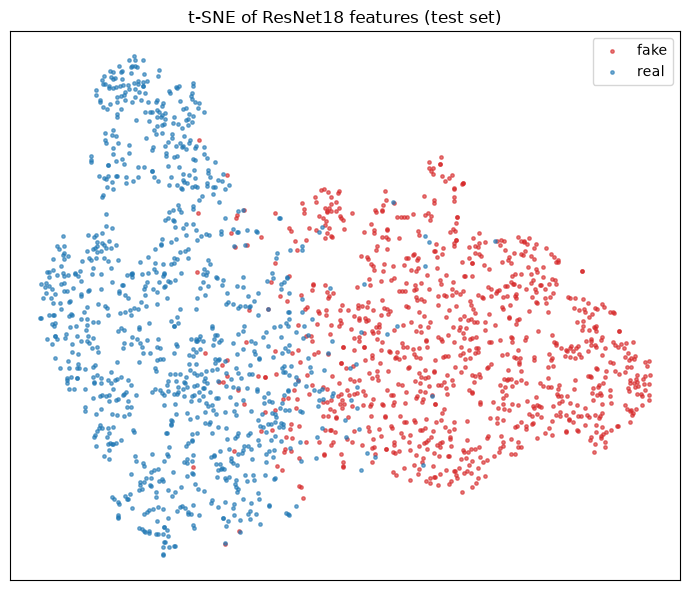

In [11]:
# t-SNE: how the final model's 512-d features separate real from fake (2,000 random test images)
from sklearn.manifold import TSNE
sub = np.random.RandomState(0).choice(len(test_ds), 2000, replace=False)
feat_model = copy.deepcopy(final_model).to(device).eval()
feat_model.fc = nn.Identity()
feats, labs = [], []
with torch.no_grad():
    for x, yy in DataLoader(Subset(test_ds, sub), batch_size=128, num_workers=WORKERS):
        feats.append(feat_model(x.to(device)).float().cpu()); labs.append(yy)
feats, labs = torch.cat(feats).numpy(), torch.cat(labs).numpy()
emb = TSNE(n_components=2, random_state=0, init="pca").fit_transform(feats)
plt.figure(figsize=(7, 6))
for c, colour in [(0, "tab:red"), (1, "tab:blue")]:
    plt.scatter(*emb[labs == c].T, s=6, alpha=0.6, c=colour, label=CLASSES[c])
plt.legend(); plt.title("t-SNE of ResNet18 features (test set)"); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.savefig(OUTPUTS / "02_tsne.png", dpi=120); plt.show()

## 8. Summary
- The learning-rate experiment justifies the chosen learning rate.
- The baseline comparison shows what transfer learning and full fine-tuning add.
- The final model is saved as `models/resnet18_ai_vs_real.pth`; every graph is saved in `outputs/`.

Next: **03 — Tiny-GenImage fine-tuning, unseen-generator test and Misinfo evaluation**.